<a href="https://colab.research.google.com/github/shreyanshsamaje7-prog/BIS_LAB/blob/main/swarm_optimisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration 1: Best objective = 2337.3025
Iteration 2: Best objective = 2337.3025
Iteration 3: Best objective = 2337.3025
Iteration 4: Best objective = 2317.3099
Iteration 5: Best objective = 2134.6233
Iteration 6: Best objective = 2030.0686
Iteration 7: Best objective = 1919.0342
Iteration 8: Best objective = 1919.0342
Iteration 9: Best objective = 1919.0342
Iteration 10: Best objective = 1913.0478
Iteration 11: Best objective = 1585.1524
Iteration 12: Best objective = 1585.1524
Iteration 13: Best objective = 1585.1524
Iteration 14: Best objective = 1585.1524
Iteration 15: Best objective = 1487.7212
Iteration 16: Best objective = 1487.7212
Iteration 17: Best objective = 1466.2040
Iteration 18: Best objective = 1466.2040
Iteration 19: Best objective = 1452.4535
Iteration 20: Best objective = 1439.2588
Iteration 21: Best objective = 1419.3839
Iteration 22: Best objective = 1419.3839
Iteration 23: Best objective = 1319.9574
Iteration 24: Best objective = 1319.9574
Iteration 25: Best object

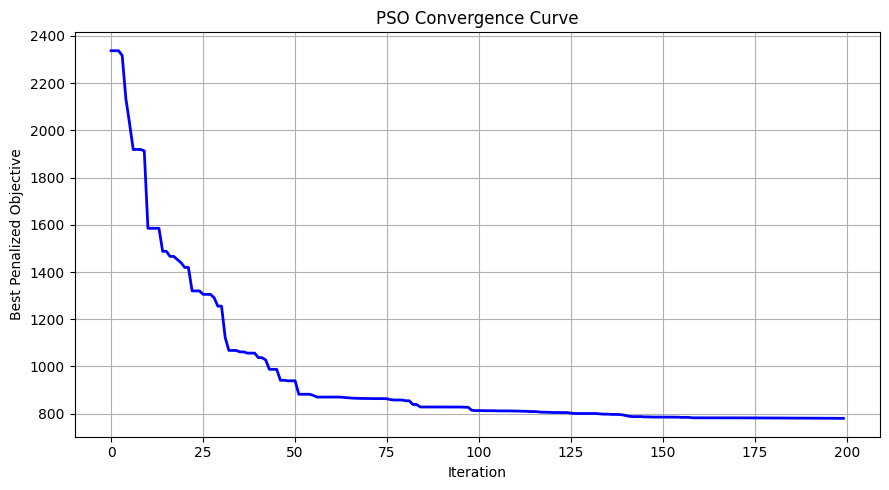

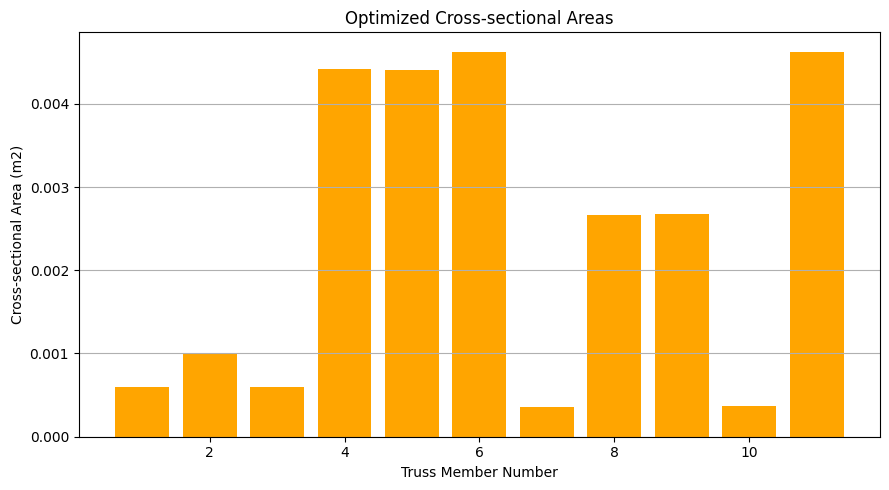

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# 1. STRUCTURAL MODEL: 2D STEEL TRUSS
# =====================================================

nodes = np.array([
    [0.0, 0.0],   # Node 0
    [4.0, 0.0],   # Node 1
    [8.0, 0.0],   # Node 2
    [12.0, 0.0],  # Node 3
    [2.0, 3.0],   # Node 4
    [6.0, 3.0],   # Node 5
    [10.0, 3.0]   # Node 6
])

members = np.array([
    [0, 1], [1, 2], [2, 3],
    [4, 5], [5, 6],
    [0, 4], [4, 1],
    [1, 5], [5, 2],
    [2, 6], [6, 3]
])

n_nodes = len(nodes)
n_members = len(members)
ndof = 2 * n_nodes

# =====================================================
# 2. MATERIAL PROPERTIES
# =====================================================

E = 200e9                  # Young's modulus (Pa)
rho = 7850                 # Density (kg/m3)
g = 9.81                   # Gravity (m/s2)

fy = 250e6                 # Yield stress (Pa)
FS = 1.5                   # Safety factor
sigma_allow = fy / FS

# Euler buckling effective length factor
K = 1.0

# =====================================================
# 3. LOADING AND BOUNDARY CONDITIONS
# =====================================================

F = np.zeros(ndof)

# Vertical loads at top nodes 4, 5 and 6
F[2*4 + 1] = -100e3
F[2*5 + 1] = -100e3
F[2*6 + 1] = -100e3

# Node 0: pinned support (ux = 0, uy = 0)
# Node 3: roller support (uy = 0)

fixed_dofs = [0, 1, 2*3 + 1]

free_dofs = np.setdiff1d(
    np.arange(ndof), fixed_dofs
)

# =====================================================
# 4. MEMBER GEOMETRY
# =====================================================

lengths = []
directions = []

for m in members:

    n1, n2 = m

    dx = nodes[n2, 0] - nodes[n1, 0]
    dy = nodes[n2, 1] - nodes[n1, 1]

    L = np.sqrt(dx**2 + dy**2)

    c = dx / L
    s = dy / L

    lengths.append(L)
    directions.append([c, s])

lengths = np.array(lengths)
directions = np.array(directions)

# =====================================================
# 5. STRUCTURAL ANALYSIS USING FEM
# =====================================================

def structural_analysis(A):

    K_global = np.zeros((ndof, ndof))

    for i, (n1, n2) in enumerate(members):

        L = lengths[i]
        c, s = directions[i]

        k_local = (E * A[i] / L) * np.array([
            [c*c, c*s, -c*c, -c*s],
            [c*s, s*s, -c*s, -s*s],
            [-c*c, -c*s, c*c, c*s],
            [-c*s, -s*s, c*s, s*s]
        ])

        dofs = [
            2*n1, 2*n1+1,
            2*n2, 2*n2+1
        ]

        K_global[np.ix_(dofs, dofs)] += k_local

    # Solve displacement equations
    K_reduced = K_global[np.ix_(
        free_dofs, free_dofs
    )]

    F_reduced = F[free_dofs]

    try:
        U = np.zeros(ndof)

        U[free_dofs] = np.linalg.solve(
            K_reduced, F_reduced
        )

    except np.linalg.LinAlgError:
        return None, None, None

    # Calculate member stresses and axial forces
    stresses = np.zeros(n_members)
    axial_forces = np.zeros(n_members)

    for i, (n1, n2) in enumerate(members):

        c, s = directions[i]
        L = lengths[i]

        dofs = [
            2*n1, 2*n1+1,
            2*n2, 2*n2+1
        ]

        u_member = U[dofs]

        extension = np.dot(
            np.array([-c, -s, c, s]),
            u_member
        )

        strain = extension / L

        stresses[i] = E * strain

        axial_forces[i] = stresses[i] * A[i]

    reactions = K_global @ U - F

    return U, stresses, axial_forces


# =====================================================
# 6. OBJECTIVE FUNCTION
# =====================================================

def objective(A):

    # Structural analysis
    U, stresses, forces = structural_analysis(A)

    if U is None:
        return 1e20

    # Total structural mass
    mass = rho * np.sum(A * lengths)

    # Maximum nodal displacement
    displacement = np.max(
        np.sqrt(
            U[0::2]**2 + U[1::2]**2
        )
    )

    # Stress utilization
    utilization = np.zeros(n_members)

    for i in range(n_members):

        if forces[i] >= 0:

            # Tensile stress constraint
            capacity = sigma_allow * A[i]

        else:

            # Euler buckling capacity
            I = A[i]**2 / 12.0

            Pcr = (
                np.pi**2 * E * I
                / (K * lengths[i])**2
            )

            # Compressive capacity
            capacity = min(
                sigma_allow * A[i],
                Pcr / FS
            )

        utilization[i] = abs(forces[i]) / capacity

    # Constraint violations
    stress_violation = np.maximum(
        utilization - 1.0, 0
    )

    displacement_limit = 0.020

    displacement_violation = max(
        displacement / displacement_limit - 1,
        0
    )

    # Penalty function
    penalty = (
        np.sum(stress_violation**2)
        + displacement_violation**2
    )

    # Penalized objective
    return mass + 1e6 * penalty


# =====================================================
# 7. PARTICLE SWARM OPTIMIZATION PARAMETERS
# =====================================================

n_particles = 40
n_iterations = 200

n_variables = n_members

lower_bound = np.ones(n_variables) * 1e-4
upper_bound = np.ones(n_variables) * 0.02

w = 0.7       # Inertia weight
c1 = 1.5      # Cognitive coefficient
c2 = 1.5      # Social coefficient

# =====================================================
# 8. INITIALIZE PARTICLES
# =====================================================

np.random.seed(42)

position = np.random.uniform(
    lower_bound,
    upper_bound,
    (n_particles, n_variables)
)

velocity = np.zeros(
    (n_particles, n_variables)
)

pbest_position = position.copy()

pbest_score = np.array([
    objective(p) for p in position
])

gbest_index = np.argmin(pbest_score)

gbest_position = pbest_position[
    gbest_index
].copy()

gbest_score = pbest_score[gbest_index]

history = []

# =====================================================
# 9. PSO ITERATION
# =====================================================

for iteration in range(n_iterations):

    for i in range(n_particles):

        r1 = np.random.rand(n_variables)
        r2 = np.random.rand(n_variables)

        velocity[i] = (
            w * velocity[i]
            + c1 * r1 * (
                pbest_position[i] - position[i]
            )
            + c2 * r2 * (
                gbest_position - position[i]
            )
        )

        position[i] += velocity[i]

        # Boundary handling
        position[i] = np.clip(
            position[i],
            lower_bound,
            upper_bound
        )

        score = objective(position[i])

        # Update personal best
        if score < pbest_score[i]:

            pbest_score[i] = score

            pbest_position[i] = position[i].copy()

        # Update global best
        if score < gbest_score:

            gbest_score = score

            gbest_position = position[i].copy()

    history.append(gbest_score)

    print(
        f"Iteration {iteration+1}: "
        f"Best objective = {gbest_score:.4f}"
    )

# =====================================================
# 10. FINAL OPTIMIZED RESULTS
# =====================================================

U, stresses, forces = structural_analysis(
    gbest_position
)

mass = rho * np.sum(
    gbest_position * lengths
)

weight = mass * g

max_displacement = np.max(
    np.sqrt(U[0::2]**2 + U[1::2]**2)
)

print("\n========== OPTIMIZATION RESULTS ==========")

print("Optimized Member Areas (m2):")

for i, area in enumerate(gbest_position):

    print(
        f"Member {i+1}: {area:.6f} m2"
    )

print(f"\nTotal Mass = {mass:.3f} kg")

print(f"Total Weight = {weight:.3f} N")

print(
    f"Maximum Displacement = "
    f"{max_displacement*1000:.4f} mm"
)

print("\nMember Stresses (MPa):")

for i, stress in enumerate(stresses):

    print(
        f"Member {i+1}: {stress/1e6:.3f} MPa"
    )

# =====================================================
# 11. CONVERGENCE GRAPH
# =====================================================

plt.figure(figsize=(9, 5))

plt.plot(
    history,
    color="blue",
    linewidth=2
)

plt.xlabel("Iteration")
plt.ylabel("Best Penalized Objective")
plt.title("PSO Convergence Curve")

plt.grid(True)

plt.tight_layout()
plt.show()

# =====================================================
# 12. OPTIMIZED MEMBER AREA GRAPH
# =====================================================

plt.figure(figsize=(9, 5))

plt.bar(
    np.arange(1, n_members+1),
    gbest_position,
    color="orange"
)

plt.xlabel("Truss Member Number")
plt.ylabel("Cross-sectional Area (m2)")

plt.title("Optimized Cross-sectional Areas")

plt.grid(axis="y")

plt.tight_layout()
plt.show()
